In [12]:
# %% Cell 1: config
import glob, os, math, time, json, subprocess
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "dinov2_vitb14"   
RES_H = 448                    # (must be a multiple of 14)
CTX = 5                        # recent frames kept in memory (plus frame 0)
TOPK = 10                      # neighbours per patch
TEMP = 0.07                    # softmax temperature on affinities
MAX_SEQS = 10                  # None = all val sequences
OUT_DIR = "/kaggle/working/davis_dinov2"
DATA_DIR = "/kaggle/working/data"
DAVIS_URL = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"
os.makedirs(OUT_DIR, exist_ok=True)

# ImageNet RGB mean/std (pixels scaled to 0–1). DINOv2 and V-JEPA 2 were pretrained
# with this normalization, so inputs must match. (e.g. CLIP uses different values).
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
print("device:", DEVICE)

device: cuda


In [13]:
# %% Cell 2: find or download DAVIS 
def find_davis_root():
    for base in ["/kaggle/input", DATA_DIR]:
        for pat in ["**/JPEGImages/480p", "**/JPEGImages"]:
            for hit in glob.glob(f"{base}/{pat}", recursive=True):
                root = hit.split("/JPEGImages")[0]
                if os.path.isdir(os.path.join(root, "Annotations")):
                    return root
    return None

def download_davis():
    os.makedirs(DATA_DIR, exist_ok=True)
    zip_path = os.path.join(DATA_DIR, "davis.zip")
    print("Downloading DAVIS 2017 (~800 MB)...")
    subprocess.run(["wget", "-q", "-O", zip_path, DAVIS_URL], check=True)
    subprocess.run(["unzip", "-q", zip_path, "-d", DATA_DIR], check=True)
    os.remove(zip_path)

root = find_davis_root()
if root is None:
    download_davis()
    root = find_davis_root()
if root is None:
    raise FileNotFoundError(f"Still no DAVIS. Contents of {DATA_DIR}: {os.listdir(DATA_DIR)}")

res = "480p" if os.path.isdir(os.path.join(root, "JPEGImages", "480p")) else ""
img_root = os.path.join(root, "JPEGImages", res)
ann_root = os.path.join(root, "Annotations", res)
val_lst = os.path.join(root, "ImageSets", "2017", "val.txt")
seqs = ([s.strip() for s in open(val_lst) if s.strip()]
        if os.path.exists(val_lst) else sorted(os.listdir(img_root)))
if MAX_SEQS: seqs = seqs[:MAX_SEQS]
print("Using DAVIS at", root, "|", len(seqs), "sequences")

Using DAVIS at /kaggle/working/data/DAVIS | 10 sequences


In [14]:
# %% Cell 3: model + preprocessing
def load_model():
    m = torch.hub.load("facebookresearch/dinov2", MODEL_NAME)
    return m.eval().to(DEVICE)

def to_tensor(img):
    w0, h0 = img.size
    w = max(14, round(w0 * RES_H / h0 / 14) * 14)
    x = np.asarray(img.resize((w, RES_H), Image.BICUBIC))
    x = torch.from_numpy(x).permute(2, 0, 1).float().unsqueeze(0) / 255
    return (x - MEAN) / STD

@torch.no_grad()
def patch_features(model, x):
    out = model.forward_features(x.to(DEVICE))
    p = out["x_norm_patchtokens"][0]                 # (N, D)
    return F.normalize(p, dim=-1), x.shape[-2] // 14, x.shape[-1] // 14

def mask_to_patch_labels(mask, K, h, w):
    m = torch.from_numpy(mask).long().clamp(max=K)
    onehot = F.one_hot(m, K + 1).permute(2, 0, 1).float().unsqueeze(0)
    lab = F.adaptive_avg_pool2d(onehot, (h, w))[0].flatten(1).T   # (N, K+1)
    return lab.to(DEVICE)

In [15]:
# %% Cell 4: label propagation
@torch.no_grad()
def propagate(feats, first_labels):
    preds = [first_labels]
    for t in range(1, len(feats)):
        ids = [0] + list(range(max(1, t - CTX), t))  # frame 0 + recent frames
        Mf = torch.cat([feats[i] for i in ids])
        Ml = torch.cat([preds[i] for i in ids])
        A = feats[t] @ Mf.T                          # (N, M) cosine affinities
        vals, idx = A.topk(min(TOPK, A.shape[1]), dim=1)
        w = F.softmax(vals / TEMP, dim=1)            # (N, TOPK)
        preds.append((w.unsqueeze(-1) * Ml[idx]).sum(1))
    return preds

def labels_to_mask(p, hw, out_hw):
    h, w = hw
    x = p.T.reshape(1, -1, h, w)
    x = F.interpolate(x, size=out_hw, mode="bilinear", align_corners=False)
    return x[0].argmax(0).cpu().numpy().astype(np.uint8)

def run_sequence(model, frames, first_mask, K):
    feats, hw = [], None
    for im in frames:
        f, h, w = patch_features(model, to_tensor(im))
        feats.append(f); hw = (h, w)
    first = mask_to_patch_labels(first_mask, K, *hw)
    probs = propagate(feats, first)
    out_hw = (frames[0].size[1], frames[0].size[0])
    masks = [labels_to_mask(p, hw, out_hw) for p in probs]
    del feats, probs
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return masks

In [16]:
# %% Cell 5: metrics (J = IoU, F = boundary F-measure)
def jaccard(pred, gt):
    union = np.logical_or(pred, gt).sum()
    return 1.0 if union == 0 else np.logical_and(pred, gt).sum() / union

def boundary_f(pred, gt, tol_ratio=0.008):
    if pred.sum() == 0 and gt.sum() == 0: return 1.0
    if pred.sum() == 0 or gt.sum() == 0: return 0.0
    tol = max(1, int(round(tol_ratio * math.hypot(*gt.shape))))
    bnd = lambda m: m ^ ndimage.binary_erosion(m, border_value=0)
    bp, bg = bnd(pred), bnd(gt)
    dt_g = ndimage.distance_transform_edt(~bg)
    dt_p = ndimage.distance_transform_edt(~bp)
    prec = (dt_g[bp] <= tol).mean() if bp.any() else 0.0
    rec = (dt_p[bg] <= tol).mean() if bg.any() else 0.0
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

def score_sequence(preds, gts, K):
    J, Fs = [], []
    for k in range(1, K + 1):                        # per object, frames 1..end
        for p, g in zip(preds[1:], gts[1:]):
            J.append(jaccard(p == k, g == k))
            Fs.append(boundary_f(p == k, g == k))
    J, Fs = np.mean(J), np.mean(Fs)
    return {"J": float(J), "F": float(Fs), "JF": float((J + Fs) / 2)}

In [17]:
# %% Cell 6: run the DAVIS benchmark 
model = load_model()
all_scores = {}
for name in seqs:
    t0 = time.time()
    img_dir, ann_dir = os.path.join(img_root, name), os.path.join(ann_root, name)
    names = sorted(os.listdir(img_dir))
    frames = [Image.open(os.path.join(img_dir, n)).convert("RGB") for n in names]
    gts = [np.array(Image.open(os.path.join(ann_dir, n[:-4] + ".png"))) for n in names]
    K = int(gts[0].max())
    masks = run_sequence(model, frames, gts[0], K)
    scores = score_sequence(masks, gts, K)
    all_scores[name] = scores

    seq_out = os.path.join(OUT_DIR, name); os.makedirs(seq_out, exist_ok=True)
    for n, m in zip(names, masks):
        Image.fromarray(m).save(os.path.join(seq_out, n[:-4] + ".png"))
    print(f"{name:20s} J={scores['J']:.3f} F={scores['F']:.3f} "
          f"J&F={scores['JF']:.3f}  ({time.time()-t0:.1f}s, {len(frames)} frames)")

mean_jf = np.mean([s["JF"] for s in all_scores.values()])
print(f"\nMean J&F over {len(all_scores)} sequences: {mean_jf:.3f}")
json.dump(all_scores, open(os.path.join(OUT_DIR, "scores.json"), "w"), indent=2)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:01<00:00, 343MB/s] 


bike-packing         J=0.769 F=0.846 J&F=0.808  (19.8s, 69 frames)
blackswan            J=0.881 F=0.920 J&F=0.900  (11.4s, 50 frames)
bmx-trees            J=0.405 F=0.627 J&F=0.516  (19.3s, 80 frames)
breakdance           J=0.850 F=0.912 J&F=0.881  (18.2s, 84 frames)
camel                J=0.748 F=0.741 J&F=0.744  (19.7s, 90 frames)
car-roundabout       J=0.880 F=0.816 J&F=0.848  (16.8s, 75 frames)
car-shadow           J=0.878 F=0.878 J&F=0.878  (8.8s, 40 frames)
cows                 J=0.851 F=0.832 J&F=0.841  (23.2s, 104 frames)
dance-twirl          J=0.801 F=0.841 J&F=0.821  (19.3s, 90 frames)
dog                  J=0.808 F=0.653 J&F=0.731  (12.9s, 60 frames)

Mean J&F over 10 sequences: 0.797


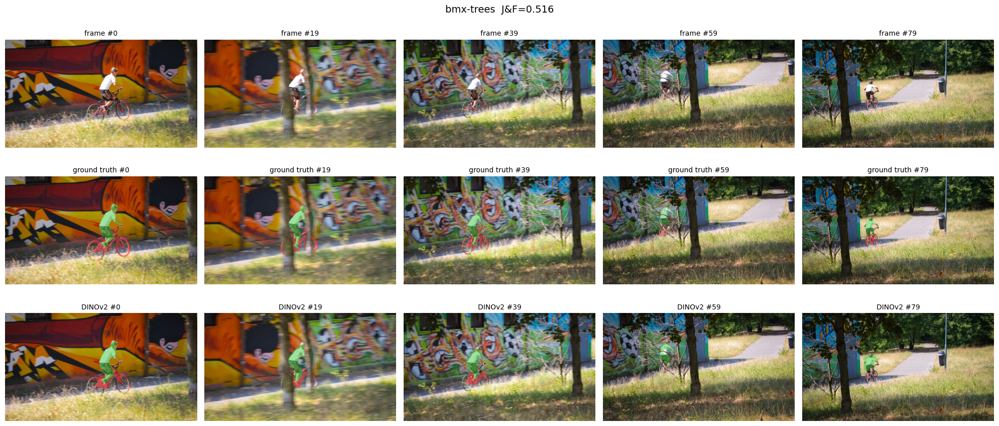

In [18]:
# visualize one sequence
import matplotlib.pyplot as plt

def colorize(mask):
    palette = np.array([[0,0,0],[255,60,60],[60,200,60],[60,120,255],
                        [255,200,0],[200,60,255],[0,220,220]], dtype=np.uint8)
    return palette[np.clip(mask, 0, len(palette)-1)]

def overlay(img, mask, alpha=0.5):
    rgb = np.asarray(img).astype(np.float32)
    col = colorize(mask).astype(np.float32)
    out = np.where((mask > 0)[..., None], (1-alpha)*rgb + alpha*col, rgb)
    return out.astype(np.uint8)

def show_sequence(name, n_frames=5):
    img_dir = os.path.join(img_root, name)
    names = sorted(os.listdir(img_dir))
    picks = np.linspace(0, len(names)-1, n_frames).astype(int)
    fig, axes = plt.subplots(3, n_frames, figsize=(4*n_frames, 9))
    for c, i in enumerate(picks):
        n = names[i][:-4]
        img = Image.open(os.path.join(img_dir, names[i])).convert("RGB")
        gt = np.array(Image.open(os.path.join(ann_root, name, n + ".png")))
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, n + ".png")))
        for r, (im, title) in enumerate([(np.asarray(img), "frame"),
                                          (overlay(img, gt), "ground truth"),
                                          (overlay(img, pr), "DINOv2")]):
            axes[r, c].imshow(im); axes[r, c].axis("off")
            axes[r, c].set_title(f"{title} #{i}", fontsize=10)
    plt.suptitle(f"{name}  J&F={all_scores[name]['JF']:.3f}", fontsize=14)
    plt.tight_layout(); plt.show()

show_sequence("bmx-trees")  

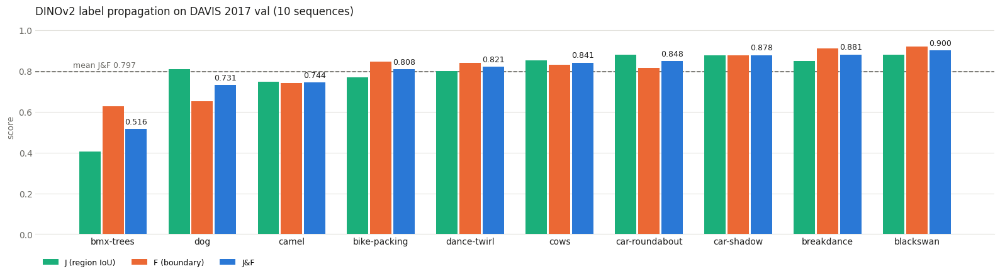

In [19]:
# per-sequence J / F / J&F bar chart
import os
import numpy as np
import matplotlib.pyplot as plt

# Uses all_scores from the benchmark cell
scores = all_scores


# Sort by J&F so the weak sequences stand out
names = sorted(scores, key=lambda n: scores[n]["JF"])
J  = np.array([scores[n]["J"]  for n in names])
F  = np.array([scores[n]["F"]  for n in names])
JF = np.array([scores[n]["JF"] for n in names])
mean_jf = JF.mean()

INK, MUTED, GRID = "#1f1f1e", "#6b6a65", "#e4e3de"
series = [("J (region IoU)", J, "#1baf7a"),
          ("F (boundary)",   F, "#eb6834"),
          ("J&F",            JF, "#2a78d6")]

x = np.arange(len(names))
w = 0.26
fig, ax = plt.subplots(figsize=(max(7, 1.6 * len(names)), 4.5))

for i, (label, vals, color) in enumerate(series):
    bars = ax.bar(x + (i - 1) * w, vals, width=w * 0.92, color=color,
                  label=label, zorder=3)
    if label == "J&F":  # label only the headline metric
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}",
                    ha="center", va="bottom", fontsize=9, color=INK)

ax.axhline(mean_jf, color=MUTED, lw=1.2, ls="--", zorder=2)
ax.text(-0.45, mean_jf + 0.012, f"mean J&F {mean_jf:.3f}",
        ha="left", va="bottom", fontsize=9, color=MUTED)

ax.set_xticks(x, names, color=INK)
ax.set_ylim(0, 1.05)
ax.set_ylabel("score", color=MUTED)
ax.set_title(f"DINOv2 label propagation on DAVIS 2017 val "
             f"({len(names)} sequences)", loc="left", color=INK, fontsize=12)
ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(axis="y", colors=MUTED, length=0)
ax.tick_params(axis="x", length=0)
ax.legend(frameon=False, ncol=3, loc="upper left",
          bbox_to_anchor=(0, -0.08), fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "davis_scores.png") if "OUT_DIR" in globals()
            else "davis_scores.png", dpi=150, bbox_inches="tight")
plt.show()

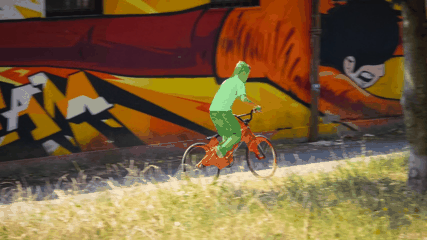

In [20]:
from IPython.display import Image as IPImage, display

def make_gif(name, path=None, fps=10):
    img_dir = os.path.join(img_root, name)
    frames = []
    for f in sorted(os.listdir(img_dir)):
        img = Image.open(os.path.join(img_dir, f)).convert("RGB")
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, f[:-4] + ".png")))
        frames.append(Image.fromarray(overlay(img, pr)).resize((427, 240)))
    path = path or f"/kaggle/working/{name}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=int(1000/fps), loop=0)
    display(IPImage(filename=path))

make_gif("bmx-trees")

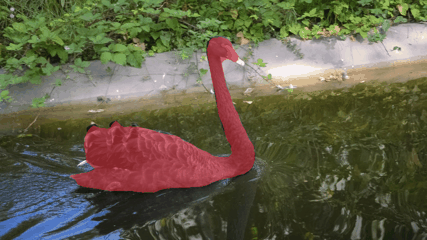

In [21]:
from IPython.display import Image as IPImage, display

def make_gif(name, path=None, fps=10):
    img_dir = os.path.join(img_root, name)
    frames = []
    for f in sorted(os.listdir(img_dir)):
        img = Image.open(os.path.join(img_dir, f)).convert("RGB")
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, f[:-4] + ".png")))
        frames.append(Image.fromarray(overlay(img, pr)).resize((427, 240)))
    path = path or f"/kaggle/working/{name}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=int(1000/fps), loop=0)
    display(IPImage(filename=path))

make_gif("blackswan")